In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Pandas: 3.0.3
NumPy: 2.4.6
Scikit-learn: 1.9.0


In [4]:
df=pd.read_csv("amazon_cleaned.csv")
print("Dataset Shape:",df.shape)
display(df.head())

Dataset Shape: (1348, 16)


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64,4.2,24269,High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,43,4.0,43994,"Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,199.0,1899.0,90,3.9,7928,【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,329.0,699.0,53,4.2,94363,The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,154.0,399.0,61,4.2,16905,[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1348 entries, 0 to 1347
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           1348 non-null   str    
 1   product_name         1348 non-null   str    
 2   category             1348 non-null   str    
 3   discounted_price     1348 non-null   float64
 4   actual_price         1348 non-null   float64
 5   discount_percentage  1348 non-null   int64  
 6   rating               1348 non-null   float64
 7   rating_count         1348 non-null   int64  
 8   about_product        1348 non-null   str    
 9   user_id              1348 non-null   str    
 10  user_name            1348 non-null   str    
 11  review_id            1348 non-null   str    
 12  review_title         1348 non-null   str    
 13  review_content       1348 non-null   str    
 14  img_link             1348 non-null   str    
 15  product_link         1348 non-null   str    
dtyp

In [7]:
print("Missing Values:")
display(df.isnull().sum())
print("Duplicate Product IDs:",
df["product_id"].duplicated().sum())
print("Duplicate Rows:",df.duplicated().sum())

Missing Values:


product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           0
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
dtype: int64

Duplicate Product IDs: 0
Duplicate Rows: 0


In [8]:
print("Target Column: rating")

print("Data Type:", df["rating"].dtype)

print("Missing Ratings:", df["rating"].isnull().sum())

print("Minimum Rating:", df["rating"].min())

print("Maximum Rating:", df["rating"].max())

print("Invalid Ratings:", (~df["rating"].between(1, 5)).sum())

print("Unique Rating Values:", df["rating"].nunique())

display(df["rating"].describe())

Target Column: rating
Data Type: float64
Missing Ratings: 0
Minimum Rating: 2.0
Maximum Rating: 5.0
Invalid Ratings: 0
Unique Rating Values: 25


count    1348.000000
mean        4.091988
std         0.295139
min         2.000000
25%         3.900000
50%         4.100000
75%         4.300000
max         5.000000
Name: rating, dtype: float64

In [9]:
#feature selection
feature_columns = [
    "discounted_price",
    "discount_percentage",
    "rating_count",
    "category"
]

target_column = "rating"

X = df[feature_columns].copy()
y = df[target_column].copy()

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())

Features Shape: (1348, 4)
Target Shape: (1348,)


,discounted_price,discount_percentage,rating_count,category
0,399.0,64,24269,Computers&Accessories|Accessories&Peripherals|...
1,199.0,43,43994,Computers&Accessories|Accessories&Peripherals|...
2,199.0,90,7928,Computers&Accessories|Accessories&Peripherals|...
3,329.0,53,94363,Computers&Accessories|Accessories&Peripherals|...
4,154.0,61,16905,Computers&Accessories|Accessories&Peripherals|...


In [10]:
print("Feature Data Types:")
display(X.dtypes)

print("Missing Values:")
display(X.isnull().sum())

print("Target Data Type:", y.dtype)
print("Target Missing Values:", y.isnull().sum())

print("Total Features:", X.shape[1])

Feature Data Types:


discounted_price       float64
discount_percentage      int64
rating_count             int64
category                   str
dtype: object

Missing Values:


discounted_price       0
discount_percentage    0
rating_count           0
category               0
dtype: int64

Target Data Type: float64
Target Missing Values: 0
Total Features: 4


In [11]:
numerical_features = [
    "discounted_price",
    "discount_percentage",
    "rating_count"
]

categorical_features = ["category"]

print("Numerical Feature Statistics:")
display(X[numerical_features].describe().T)

print("Total Unique Categories:", X["category"].nunique())

Numerical Feature Statistics:


,count,mean,std,min,25%,50%,75%,max
discounted_price,1348.0,3310.267188,7180.901370,39.0,349.0,899.0,2184.0,77990.0
discount_percentage,1348.0,46.662463,21.607716,0.0,31.0,49.0,62.0,94.0
rating_count,1348.0,17656.847923,42158.843602,2.0,1107.5,4740.0,16051.5,426973.0


Total Unique Categories: 211


In [12]:
category_counts = X["category"].value_counts()

print("Total Unique Categories:", len(category_counts))

print("Top 10 Categories:")
display(category_counts.head(10).to_frame("Product_Count"))

print("Categories With Only One Product:", (category_counts == 1).sum())

print("Categories With Fewer Than 5 Products:", (category_counts < 5).sum())

Total Unique Categories: 211
Top 10 Categories:


,Product_Count
category,
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,159
Electronics|Mobiles&Accessories|Smartphones&BasicMobiles|Smartphones,68
Electronics|WearableTechnology|SmartWatches,62
"Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions",60
"Electronics|Headphones,Earbuds&Accessories|Headphones|In-Ear",51
"Electronics|HomeTheater,TV&Video|Accessories|RemoteControls",49
Home&Kitchen|Kitchen&HomeAppliances|SmallKitchenAppliances|MixerGrinders,27
"Computers&Accessories|Accessories&Peripherals|Keyboards,Mice&InputDevices|Mice",24
"Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cleaning&Ironing|Irons,Steamers&Accessories|Irons|DryIrons",24


Categories With Only One Product: 76
Categories With Fewer Than 5 Products: 146


In [13]:
category_preview = X["category"].str.split("|", regex=False).str[0].str.strip()

category_summary = category_preview.value_counts()

print("Original Unique Categories:", X["category"].nunique())
print("Broad Unique Categories:", category_preview.nunique())

display(category_summary.to_frame("Product_Count"))

Original Unique Categories: 211
Broad Unique Categories: 9


,Product_Count
category,
Electronics,490
Home&Kitchen,447
Computers&Accessories,373
OfficeProducts,31
MusicalInstruments,2
HomeImprovement,2
Toys&Games,1
Car&Motorbike,1
Health&PersonalCare,1


In [14]:
print("Total Broad Categories:", category_preview.nunique())

print("Broad Category Distribution:")
display(category_preview.value_counts().to_frame("Product_Count"))

print("Total Products:", category_preview.value_counts().sum())

Total Broad Categories: 9
Broad Category Distribution:


,Product_Count
category,
Electronics,490
Home&Kitchen,447
Computers&Accessories,373
OfficeProducts,31
MusicalInstruments,2
HomeImprovement,2
Toys&Games,1
Car&Motorbike,1
Health&PersonalCare,1


Total Products: 1348


In [15]:
major_categories = [
    "Electronics",
    "Home&Kitchen",
    "Computers&Accessories",
    "OfficeProducts"
]

X["category_grouped"] = category_preview.where(
    category_preview.isin(major_categories),
    "Other"
)

X = X.drop(columns=["category"])

categorical_features = ["category_grouped"]

print("Final Features:")
display(X.head())

print("Final Feature Shape:", X.shape)

print("Final Category Distribution:")
display(X["category_grouped"].value_counts())

Final Features:


,discounted_price,discount_percentage,rating_count,category_grouped
0,399.0,64,24269,Computers&Accessories
1,199.0,43,43994,Computers&Accessories
2,199.0,90,7928,Computers&Accessories
3,329.0,53,94363,Computers&Accessories
4,154.0,61,16905,Computers&Accessories


Final Feature Shape: (1348, 4)
Final Category Distribution:


category_grouped
Electronics              490
Home&Kitchen             447
Computers&Accessories    373
OfficeProducts            31
Other                      7
Name: count, dtype: int64

Correlation Matrix:


,discounted_price,discount_percentage,rating_count,rating
discounted_price,1.0000,-0.2364,-0.0241,0.1272
discount_percentage,-0.2364,1.0000,0.0034,-0.1622
rating_count,-0.0241,0.0034,1.0000,0.0975
rating,0.1272,-0.1622,0.0975,1.0000


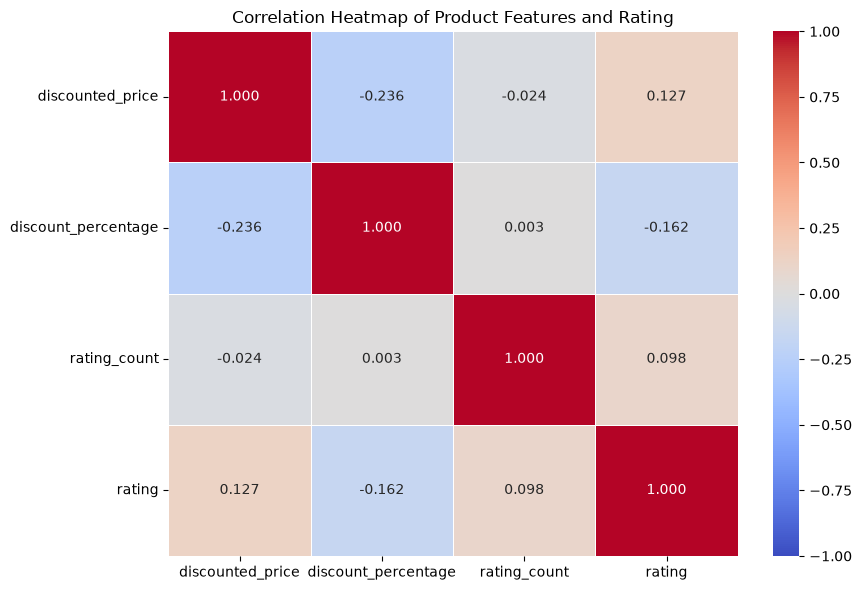

In [16]:
correlation_data = X[numerical_features].copy()
correlation_data["rating"] = y

correlation_matrix = correlation_data.corr(method="pearson")

print("Correlation Matrix:")
display(correlation_matrix.round(4))

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Product Features and Rating")
plt.tight_layout()
plt.show()

### Important Findings

**1. Discount Percentage (−0.1622)**

There is a weak negative correlation between discount percentage and product ratings. As discounts increase, ratings tend to decrease slightly. This finding is consistent with the results of Task 2. However, correlation does not imply causation, meaning higher discounts do not necessarily cause lower ratings.

**2. Discounted Price (+0.1272)**

There is a weak positive correlation between discounted price and product ratings. Higher-priced products tend to receive slightly higher ratings, but the relationship is not strong.

**3. Rating Count (+0.0975)**

There is a very weak positive correlation between rating count and product ratings. Products with more customer ratings tend to have slightly higher average ratings.

### Key Observation

All three numerical features show weak linear relationships with product ratings. Therefore, comparing Linear Regression with more advanced machine learning models, such as Random Forest and Gradient Boosting, will help determine whether nonlinear relationships can improve prediction accuracy.

At this stage, it is not possible to determine which model will perform best. The final decision will be based on evaluation metrics such as MAE, RMSE, R², and cross-validation results.

Feature Skewness:


,Skewness
discounted_price,4.296700
discount_percentage,-0.237480
rating_count,5.687163


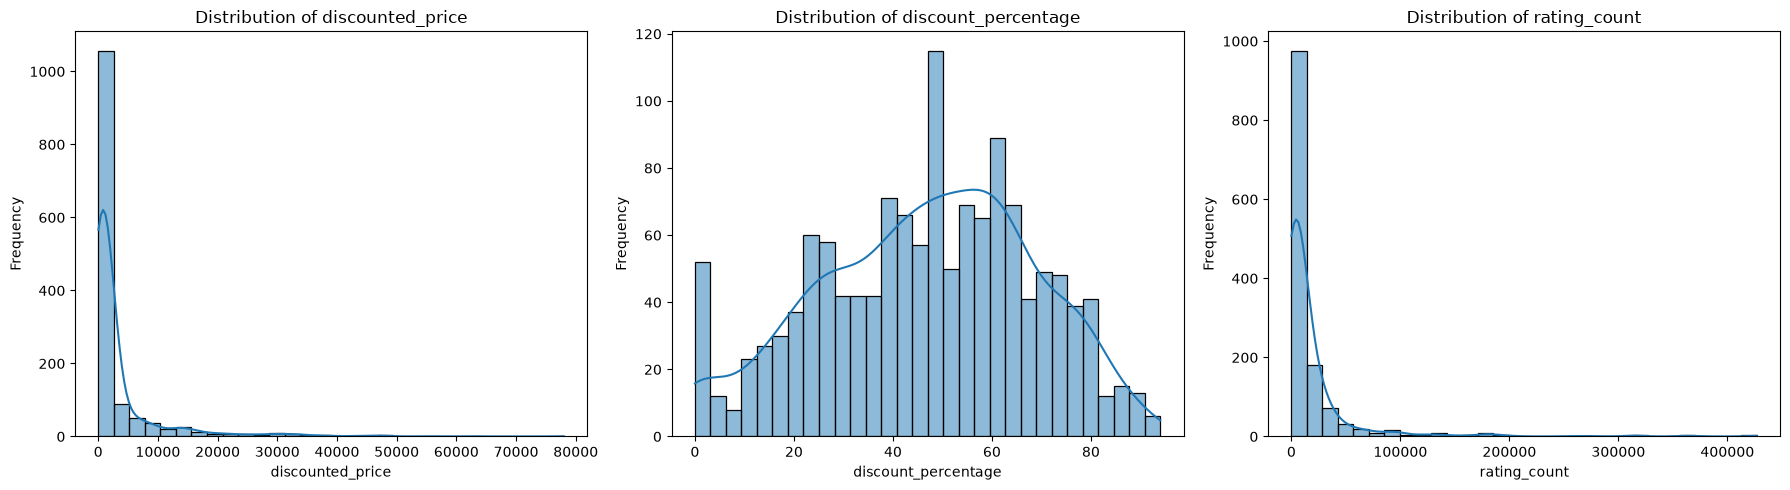

In [17]:
#skewness analysis
print("Feature Skewness:")
display(X[numerical_features].skew().to_frame("Skewness"))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, column in enumerate(numerical_features):
    sns.histplot(
        X[column],
        bins=30,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

Rating Statistics:


count    1348.000000
mean        4.091988
std         0.295139
min         2.000000
25%         3.900000
50%         4.100000
75%         4.300000
max         5.000000
Name: rating, dtype: float64

Rating Skewness: -1.2455


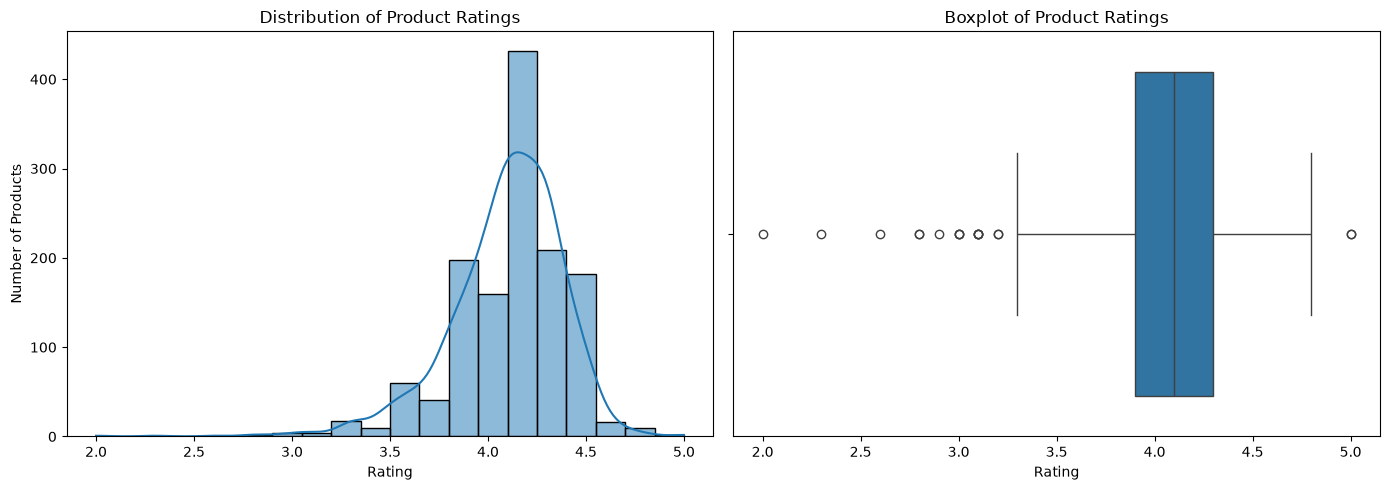

In [18]:
#ratin distribution analysis
print("Rating Statistics:")
display(y.describe())

print("Rating Skewness:", round(y.skew(), 4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    y,
    bins=20,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Product Ratings")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Number of Products")

sns.boxplot(
    x=y,
    ax=axes[1]
)

axes[1].set_title("Boxplot of Product Ratings")
axes[1].set_xlabel("Rating")

plt.tight_layout()
plt.show()

Category-wise Rating Statistics:


,count,mean,median,std,min,max
category_grouped,,,,,,
OfficeProducts,31,4.3097,4.3,0.1491,4.0,4.5
Computers&Accessories,373,4.1547,4.2,0.2612,3.3,5.0
Electronics,490,4.0778,4.1,0.2740,2.8,4.7
Other,7,4.0571,4.0,0.2573,3.8,4.5
Home&Kitchen,447,4.0407,4.1,0.3347,2.0,4.8


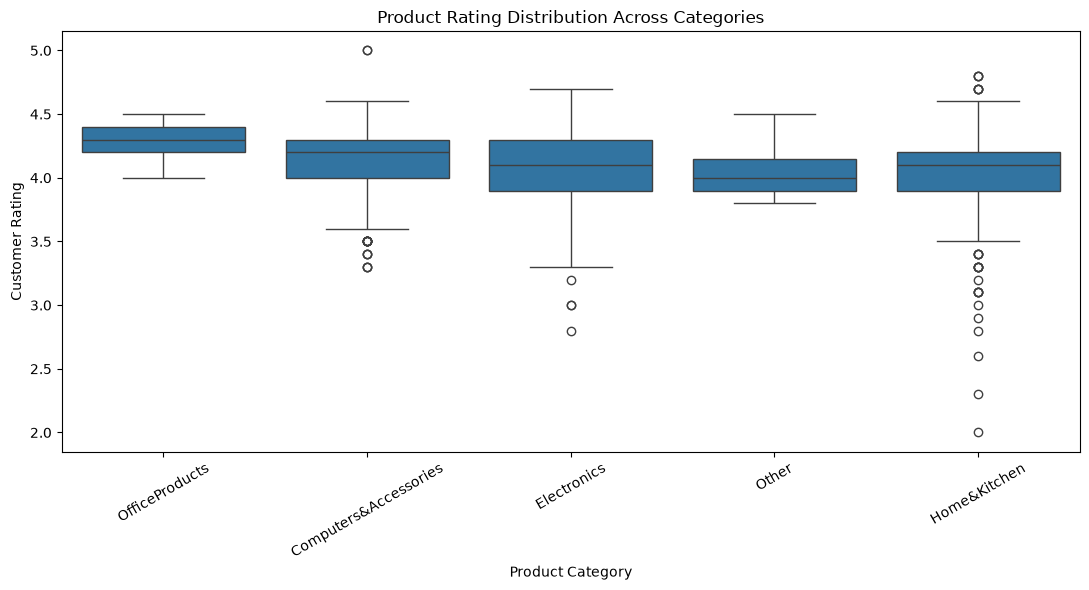

In [19]:
category_rating_data = X[["category_grouped"]].copy()
category_rating_data["rating"] = y

category_rating_summary = (
    category_rating_data
    .groupby("category_grouped")["rating"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .sort_values("mean", ascending=False)
)

print("Category-wise Rating Statistics:")
display(category_rating_summary.round(4))

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=category_rating_data,
    x="category_grouped",
    y="rating",
    order=category_rating_summary.index
)

plt.title("Product Rating Distribution Across Categories")
plt.xlabel("Product Category")
plt.ylabel("Customer Rating")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Step 4 – Important Findings: Category-Wise Rating Analysis

**1. OfficeProducts – Highest Average Rating (4.31)**

The OfficeProducts category has the highest average product rating of 4.31. However, this category contains only 31 products, so the result should be interpreted cautiously due to the relatively small sample size.

**2. Computers & Accessories – Strong Ratings (4.15)**

With 373 products, the Computers & Accessories category has an average rating of 4.15, which is higher than the overall dataset average of 4.09. This indicates relatively strong customer ratings in this category.

**3. Home & Kitchen – Lowest Average Rating (4.04)**

The Home & Kitchen category contains 447 products and has the lowest average rating of 4.04. It also has the highest rating standard deviation (0.3347), indicating greater variation in customer ratings compared to other categories.

**4. Potential Importance of Category as a Predictive Feature**

The differences in average ratings across product categories suggest that `category_grouped` may provide useful information for predicting product ratings. However, its actual predictive contribution must be confirmed through model evaluation and feature importance analysis.

### Step 4 – Conclusion

The category-wise analysis reveals noticeable differences in average product ratings. OfficeProducts has the highest average rating, while Home & Kitchen has the lowest and shows the greatest rating variability. These findings suggest that product category could be a valuable feature in the predictive rating model. Further machine learning evaluation will determine whether including category information improves prediction accuracy.

In [20]:
#log transformation
log_preview = pd.DataFrame({
    "discounted_price_original": X["discounted_price"],
    "discounted_price_log": np.log1p(X["discounted_price"]),
    "rating_count_original": X["rating_count"],
    "rating_count_log": np.log1p(X["rating_count"])
})

print("Skewness Before and After Log Transformation:")

skewness_comparison = pd.DataFrame({
    "Original_Skewness": [
        X["discounted_price"].skew(),
        X["rating_count"].skew()
    ],
    "Log_Transformed_Skewness": [
        log_preview["discounted_price_log"].skew(),
        log_preview["rating_count_log"].skew()
    ]
}, index=["discounted_price", "rating_count"])

display(skewness_comparison.round(4))
display(log_preview.head())

Skewness Before and After Log Transformation:


,Original_Skewness,Log_Transformed_Skewness
discounted_price,4.2967,0.5912
rating_count,5.6872,-0.5477


,discounted_price_original,discounted_price_log,rating_count_original,rating_count_log
0,399.0,5.991465,24269,10.096996
1,199.0,5.298317,43994,10.691831
2,199.0,5.298317,7928,8.978282
3,329.0,5.799093,94363,11.454915
4,154.0,5.043425,16905,9.735424


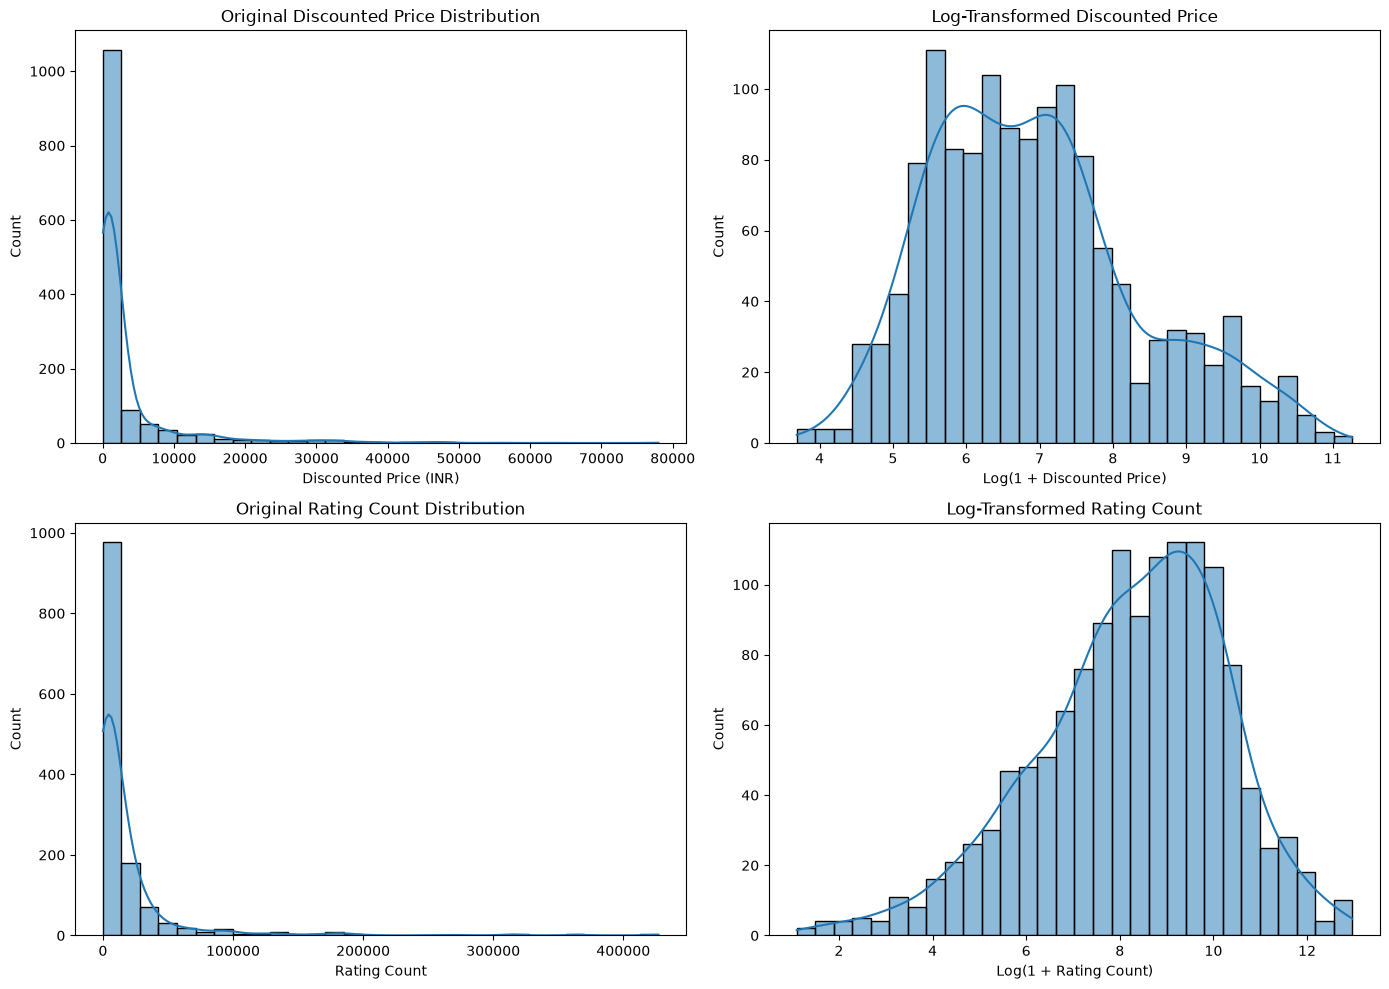

In [21]:
#befor and after visualisation
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(
    X["discounted_price"],
    bins=30,
    kde=True,
    ax=axes[0, 0]
)

axes[0, 0].set_title("Original Discounted Price Distribution")
axes[0, 0].set_xlabel("Discounted Price (INR)")

sns.histplot(
    log_preview["discounted_price_log"],
    bins=30,
    kde=True,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Log-Transformed Discounted Price")
axes[0, 1].set_xlabel("Log(1 + Discounted Price)")

sns.histplot(
    X["rating_count"],
    bins=30,
    kde=True,
    ax=axes[1, 0]
)

axes[1, 0].set_title("Original Rating Count Distribution")
axes[1, 0].set_xlabel("Rating Count")

sns.histplot(
    log_preview["rating_count_log"],
    bins=30,
    kde=True,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Log-Transformed Rating Count")
axes[1, 1].set_xlabel("Log(1 + Rating Count)")

plt.tight_layout()
plt.show()

In [22]:
#train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Total Products:", len(X))
print("Training Products:", len(X_train))
print("Testing Products:", len(X_test))

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Total Products: 1348
Training Products: 1078
Testing Products: 270
Training Features Shape: (1078, 4)
Testing Features Shape: (270, 4)
Training Target Shape: (1078,)
Testing Target Shape: (270,)


In [23]:
#test validation
split_summary = pd.DataFrame({
    "Training": y_train.describe(),
    "Testing": y_test.describe()
})

print("Training vs Testing Rating Statistics:")
display(split_summary.round(4))

print("Training Missing Ratings:", y_train.isnull().sum())
print("Testing Missing Ratings:", y_test.isnull().sum())

print("Training Mean Rating:", round(y_train.mean(), 4))
print("Testing Mean Rating:", round(y_test.mean(), 4))

Training vs Testing Rating Statistics:


,Training,Testing
count,1078.0000,270.0000
mean,4.0965,4.0741
std,0.2888,0.3191
min,2.3000,2.0000
25%,4.0000,3.9000
50%,4.1000,4.1000
75%,4.3000,4.3000
max,5.0000,5.0000


Training Missing Ratings: 0
Testing Missing Ratings: 0
Training Mean Rating: 4.0965
Testing Mean Rating: 4.0741


In [24]:
#preproccessing pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

In [25]:
#defining them
log_features = [
    "discounted_price",
    "rating_count"
]

regular_numeric_features = [
    "discount_percentage"
]

categorical_features = [
    "category_grouped"
]

log_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler())
])

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("log_features", log_pipeline, log_features),
    ("numeric_features", numeric_pipeline, regular_numeric_features),
    ("categorical_features", categorical_pipeline, categorical_features)
])

print("Preprocessing Pipeline Created Successfully!")
print(preprocessor)


Preprocessing Pipeline Created Successfully!
ColumnTransformer(transformers=[('log_features',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('log_transform',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),
                                                 ('scaler', StandardScaler())]),
                                 ['discounted_price', 'rating_count']),
                                ('numeric_features',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['discount_percentage']),
     

In [26]:
#preprocessing pipeline validation
from sklearn.base import clone

preprocessor_check = clone(preprocessor)

X_train_transformed = preprocessor_check.fit_transform(X_train)

X_test_transformed = preprocessor_check.transform(X_test)

print("Original Training Shape:", X_train.shape)
print("Transformed Training Shape:", X_train_transformed.shape)

print("Original Testing Shape:", X_test.shape)
print("Transformed Testing Shape:", X_test_transformed.shape)

print("Transformed Feature Names:")
print(preprocessor_check.get_feature_names_out())

print("Missing Values After Preprocessing:")
print(np.isnan(X_train_transformed).sum())
print(np.isnan(X_test_transformed).sum())

Original Training Shape: (1078, 4)
Transformed Training Shape: (1078, 8)
Original Testing Shape: (270, 4)
Transformed Testing Shape: (270, 8)
Transformed Feature Names:
['log_features__discounted_price' 'log_features__rating_count'
 'numeric_features__discount_percentage'
 'categorical_features__category_grouped_Computers&Accessories'
 'categorical_features__category_grouped_Electronics'
 'categorical_features__category_grouped_Home&Kitchen'
 'categorical_features__category_grouped_OfficeProducts'
 'categorical_features__category_grouped_Other']
Missing Values After Preprocessing:
0
0


In [27]:
#baseline model
baseline_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", DummyRegressor(strategy="mean"))
])

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print("Baseline Model: Dummy Regressor")
print("Predicted Average Rating:", round(baseline_predictions[0], 4))
print("MAE:", round(baseline_mae, 4))
print("RMSE:", round(baseline_rmse, 4))
print("R²:", round(baseline_r2, 4))

Baseline Model: Dummy Regressor
Predicted Average Rating: 4.0965
MAE: 0.2296
RMSE: 0.3193
R²: -0.0049


In [28]:
#saving baseline results
model_results = []

model_results.append({
    "Model": "Dummy Regressor",
    "MAE": baseline_mae,
    "RMSE": baseline_rmse,
    "R2": baseline_r2
})

results_df = pd.DataFrame(model_results)

print("Initial Model Comparison:")
display(results_df.round(4))

Initial Model Comparison:


,Model,MAE,RMSE,R2
0,Dummy Regressor,0.2296,0.3193,-0.0049


In [29]:
#linear regression model training
linear_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_train_predictions = linear_model.predict(X_train)

print("Linear Regression Model Trained Successfully!")

print("Training MAE:", round(mean_absolute_error(y_train, linear_train_predictions), 4))

print("Training R²:", round(r2_score(y_train, linear_train_predictions), 4))

Linear Regression Model Trained Successfully!
Training MAE: 0.2006
Training R²: 0.1199


In [30]:
#5-Fold
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

linear_cv = cross_validate(
    linear_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

linear_cv_results = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "MAE": -linear_cv["test_MAE"],
    "RMSE": -linear_cv["test_RMSE"],
    "R2": linear_cv["test_R2"]
})

print("Linear Regression - 5-Fold Cross-Validation Results:")
display(linear_cv_results.round(4))

print("Average CV MAE:", round(linear_cv_results["MAE"].mean(), 4))
print("Average CV RMSE:", round(linear_cv_results["RMSE"].mean(), 4))
print("Average CV R²:", round(linear_cv_results["R2"].mean(), 4))

Linear Regression - 5-Fold Cross-Validation Results:


,Fold,MAE,RMSE,R2
0,1,0.2318,0.3250,-0.0000
1,2,0.1782,0.2311,0.1251
2,3,0.1817,0.2372,0.1062
3,4,0.2137,0.2889,0.1584
4,5,0.2064,0.2718,0.1284


Average CV MAE: 0.2024
Average CV RMSE: 0.2708
Average CV R²: 0.1036


## Important Findings – Linear Regression Cross-Validation Analysis

### 1. Training vs. Cross-Validation Performance

| Metric | Training | CV Average |
|---|---|---|
| MAE | 0.2006 | 0.2024 |
| R² | 0.1199 | 0.1036 |

The training and cross-validation results are relatively close, indicating no significant evidence of overfitting. The model demonstrates reasonably consistent performance between training and validation datasets.

### 2. R² Score = 0.1036

The average cross-validation R² score of 0.1036 indicates that the Linear Regression model explains approximately 10.36% of the variation in product ratings across the validation folds.

This suggests relatively weak predictive power, as most of the variation in customer ratings remains unexplained by the selected features.

### 3. Fold 1 – R² ≈ 0

In the first validation fold, the model achieved an R² score close to zero, indicating performance comparable to predicting the mean rating of that validation fold.

However, the remaining folds produced positive R² scores, suggesting that the model captures some predictive relationships.

This variation indicates that model performance depends partly on the characteristics of the product samples used for validation.

### 4. Baseline Model Comparison

The Dummy Regressor achieved a test MAE of 0.2296, while Linear Regression achieved an average cross-validation MAE of 0.2024.

Although Linear Regression shows a lower prediction error, these results were obtained from different evaluation samples. Therefore, a direct percentage improvement cannot be calculated reliably.

For a fair comparison, all models will be evaluated using the same cross-validation folds and evaluation metrics.

### Conclusion

The Linear Regression model demonstrates relatively stable performance with no major signs of overfitting. However, its low cross-validation R² score (0.1036) indicates limited predictive accuracy.

These findings suggest that linear relationships alone may not adequately explain product ratings. Therefore, Random Forest and Gradient Boosting will be evaluated to determine whether nonlinear models can capture more complex patterns and improve prediction performance.

In [31]:
#random forest regressor
random_forest_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

rf_train_predictions = random_forest_model.predict(X_train)

print("Random Forest Model Trained Successfully!")
print("Training MAE:", round(mean_absolute_error(y_train, rf_train_predictions), 4))
print("Training RMSE:", round(np.sqrt(mean_squared_error(y_train, rf_train_predictions)), 4))
print("Training R²:", round(r2_score(y_train, rf_train_predictions), 4))

Random Forest Model Trained Successfully!
Training MAE: 0.1594
Training RMSE: 0.2188
Training R²: 0.4257


In [32]:
rf_cv = cross_validate(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

rf_cv_results = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "MAE": -rf_cv["test_MAE"],
    "RMSE": -rf_cv["test_RMSE"],
    "R2": rf_cv["test_R2"]
})

print("Random Forest - 5-Fold Cross-Validation Results:")
display(rf_cv_results.round(4))

print("Average CV MAE:", round(rf_cv_results["MAE"].mean(), 4))
print("Average CV RMSE:", round(rf_cv_results["RMSE"].mean(), 4))
print("Average CV R²:", round(rf_cv_results["R2"].mean(), 4))

Random Forest - 5-Fold Cross-Validation Results:


,Fold,MAE,RMSE,R2
0,1,0.2216,0.3144,0.0644
1,2,0.1678,0.2251,0.1696
2,3,0.1798,0.2430,0.0622
3,4,0.2077,0.2827,0.1941
4,5,0.2047,0.2739,0.1148


Average CV MAE: 0.1963
Average CV RMSE: 0.2678
Average CV R²: 0.121


Important finding: Overfitting
Random Forest Training R²
0.4257


Random Forest CV R²
0.1210

In [33]:
gradient_boosting_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=5,
        random_state=42
    ))
])

gradient_boosting_model.fit(X_train, y_train)

gb_train_predictions = gradient_boosting_model.predict(X_train)

print("Gradient Boosting Model Trained Successfully!")
print("Training MAE:", round(mean_absolute_error(y_train, gb_train_predictions), 4))
print("Training RMSE:", round(np.sqrt(mean_squared_error(y_train, gb_train_predictions)), 4))
print("Training R²:", round(r2_score(y_train, gb_train_predictions), 4))

Gradient Boosting Model Trained Successfully!
Training MAE: 0.1708
Training RMSE: 0.2306
Training R²: 0.3619


In [34]:
gb_cv = cross_validate(
    gradient_boosting_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

gb_cv_results = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "MAE": -gb_cv["test_MAE"],
    "RMSE": -gb_cv["test_RMSE"],
    "R2": gb_cv["test_R2"]
})

print("Gradient Boosting - 5-Fold Cross-Validation Results:")
display(gb_cv_results.round(4))

print("Average CV MAE:", round(gb_cv_results["MAE"].mean(), 4))
print("Average CV RMSE:", round(gb_cv_results["RMSE"].mean(), 4))
print("Average CV R²:", round(gb_cv_results["R2"].mean(), 4))

Gradient Boosting - 5-Fold Cross-Validation Results:


,Fold,MAE,RMSE,R2
0,1,0.2225,0.3178,0.0438
1,2,0.1704,0.2281,0.1473
2,3,0.1765,0.2393,0.0906
3,4,0.2168,0.2948,0.1237
4,5,0.2069,0.2806,0.0712


Average CV MAE: 0.1986
Average CV RMSE: 0.2721
Average CV R²: 0.0953


## Important Findings – Machine Learning Model Comparison

### 1. Random Forest – Best Performing Model

Random Forest currently demonstrates the best overall predictive performance among the evaluated models. It achieved the lowest cross-validation MAE (0.1963), the lowest RMSE (0.2678), and the highest R² score (0.1210).

These results indicate that Random Forest is more effective at capturing patterns in product ratings compared to Linear Regression and Gradient Boosting.

### 2. Gradient Boosting vs. Linear Regression

Gradient Boosting does not outperform Linear Regression across all evaluation metrics.

Although Gradient Boosting achieves a slightly lower MAE, its RMSE and R² scores are worse than those of Linear Regression.

This suggests that Gradient Boosting reduces the average absolute prediction error slightly but performs less effectively in terms of squared prediction errors and explained variance.

### 3. Overfitting Concerns

Both Random Forest and Gradient Boosting show noticeable differences between training and cross-validation performance.

- **Random Forest:** Training R² = 0.4257, CV R² = 0.1210.
- **Gradient Boosting:** Training R² = 0.3619, CV R² = 0.0953.

The substantial decrease in R² scores indicates potential overfitting, suggesting that both models capture patterns in the training data that do not generalize well to unseen products.

### 4. Limited Practical Prediction Accuracy

Despite achieving the best results, Random Forest explains only approximately 12.1% of the variation in product ratings across validation folds.

This indicates that the model's predictive capability remains limited. Additional relevant features, improved feature engineering, and hyperparameter optimization may be necessary to achieve better performance.

### Conclusion and Next Step

Random Forest is currently the best-performing model based on MAE, RMSE, and R². However, its relatively low cross-validation R² score and noticeable training-validation performance gap highlight limitations in generalization.

**The next step is hyperparameter tuning** to determine whether optimizing model complexity and regularization can reduce overfitting and improve prediction accuracy on unseen data.

In [35]:
cv_comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "CV_MAE": linear_cv_results["MAE"].mean(),
        "CV_RMSE": linear_cv_results["RMSE"].mean(),
        "CV_R2": linear_cv_results["R2"].mean()
    },
    {
        "Model": "Random Forest",
        "CV_MAE": rf_cv_results["MAE"].mean(),
        "CV_RMSE": rf_cv_results["RMSE"].mean(),
        "CV_R2": rf_cv_results["R2"].mean()
    },
    {
        "Model": "Gradient Boosting",
        "CV_MAE": gb_cv_results["MAE"].mean(),
        "CV_RMSE": gb_cv_results["RMSE"].mean(),
        "CV_R2": gb_cv_results["R2"].mean()
    }
])

cv_comparison = cv_comparison.sort_values("CV_MAE").reset_index(drop=True)

print("Complete Cross-Validation Model Comparison:")
display(cv_comparison.round(4))

print("Current Best Model:", cv_comparison.loc[0, "Model"])

Complete Cross-Validation Model Comparison:


,Model,CV_MAE,CV_RMSE,CV_R2
0,Random Forest,0.1963,0.2678,0.1210
1,Gradient Boosting,0.1986,0.2721,0.0953
2,Linear Regression,0.2024,0.2708,0.1036


Current Best Model: Random Forest


In [36]:
#random fores hyperparameter tuning
rf_param_distributions = {
    "model__n_estimators": [100, 200, 300, 400],
    "model__max_depth": [3, 5, 7, 10, 15, None],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [2, 5, 10, 15],
    "model__max_features": [0.7, 1.0]
}

rf_random_search = RandomizedSearchCV(
    estimator=Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", RandomForestRegressor(
            random_state=42,
            n_jobs=1
        ))
    ]),
    param_distributions=rf_param_distributions,
    n_iter=25,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

rf_random_search.fit(X_train, y_train)

print("Random Forest Hyperparameter Tuning Completed!")

print("\nBest Parameters:")
print(rf_random_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(round(-rf_random_search.best_score_, 4))

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Random Forest Hyperparameter Tuning Completed!

Best Parameters:
{'model__n_estimators': 400, 'model__min_samples_split': 10, 'model__min_samples_leaf': 5, 'model__max_features': 0.7, 'model__max_depth': None}

Best Cross-Validation MAE:
0.1945


 **mae improved after tuning**

In [37]:
tuned_rf_model = rf_random_search.best_estimator_

tuned_rf_train_predictions = tuned_rf_model.predict(X_train)

tuned_rf_train_mae = mean_absolute_error(
    y_train,
    tuned_rf_train_predictions
)

tuned_rf_train_rmse = np.sqrt(
    mean_squared_error(y_train, tuned_rf_train_predictions)
)

tuned_rf_train_r2 = r2_score(
    y_train,
    tuned_rf_train_predictions
)

print("Tuned Random Forest - Training Performance")
print("Training MAE:", round(tuned_rf_train_mae, 4))
print("Training RMSE:", round(tuned_rf_train_rmse, 4))
print("Training R²:", round(tuned_rf_train_r2, 4))
print("Tuning CV MAE:", round(-rf_random_search.best_score_, 4))

Tuned Random Forest - Training Performance
Training MAE: 0.1453
Training RMSE: 0.2041
Training R²: 0.4999
Tuning CV MAE: 0.1945


In [38]:
tuned_rf_cv = cross_validate(
    tuned_rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

tuned_rf_cv_results = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "MAE": -tuned_rf_cv["test_MAE"],
    "RMSE": -tuned_rf_cv["test_RMSE"],
    "R2": tuned_rf_cv["test_R2"]
})

print("Tuned Random Forest - 5-Fold Cross-Validation:")
display(tuned_rf_cv_results.round(4))

print("Average CV MAE:", round(tuned_rf_cv_results["MAE"].mean(), 4))
print("Average CV RMSE:", round(tuned_rf_cv_results["RMSE"].mean(), 4))
print("Average CV R²:", round(tuned_rf_cv_results["R2"].mean(), 4))

Tuned Random Forest - 5-Fold Cross-Validation:


,Fold,MAE,RMSE,R2
0,1,0.2204,0.3122,0.0774
1,2,0.1648,0.2232,0.1837
2,3,0.1798,0.2427,0.0642
3,4,0.2045,0.2801,0.2091
4,5,0.2033,0.2722,0.1256


Average CV MAE: 0.1945
Average CV RMSE: 0.2661
Average CV R²: 0.132


In [39]:
#finalholdout test evaluation
models_for_test = {
    "Dummy Regressor": baseline_model,
    "Linear Regression": linear_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model,
    "Tuned Random Forest": tuned_rf_model
}

final_test_results = []

for model_name, model in models_for_test.items():
    predictions = model.predict(X_test)

    final_test_results.append({
        "Model": model_name,
        "Test_MAE": mean_absolute_error(y_test, predictions),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "Test_R2": r2_score(y_test, predictions)
    })

final_test_df = pd.DataFrame(final_test_results)

print("Final Holdout Test Performance:")
display(final_test_df.round(4))

Final Holdout Test Performance:


,Model,Test_MAE,Test_RMSE,Test_R2
0,Dummy Regressor,0.2296,0.3193,-0.0049
1,Linear Regression,0.2163,0.2995,0.1162
2,Random Forest,0.2100,0.2976,0.1275
3,Gradient Boosting,0.2187,0.3039,0.0901
4,Tuned Random Forest,0.2070,0.2947,0.1444


**Best Model — Tuned Random Forest
0.2070
Test MAE
0.2947
Test RMSE
0.1444
Test R²**

In [41]:
#prediction error analysis
final_predictions = tuned_rf_model.predict(X_test)

error_analysis = X_test.copy()

error_analysis["Actual_Rating"] = y_test
error_analysis["Predicted_Rating"] = final_predictions

error_analysis["Error"] = (
    error_analysis["Actual_Rating"]
    - error_analysis["Predicted_Rating"]
)

error_analysis["Absolute_Error"] = error_analysis["Error"].abs()

error_analysis = error_analysis.sort_values(
    "Absolute_Error",
    ascending=False
)

print("Top 10 Products with Highest Prediction Errors:")
display(error_analysis.head(10).round(4))

print("Total Test Products:", len(error_analysis))

print("Average Absolute Error:", round(error_analysis["Absolute_Error"].mean(), 4))

print("Maximum Absolute Error:", round(error_analysis["Absolute_Error"].max(), 4))

Top 10 Products with Highest Prediction Errors:


,discounted_price,discount_percentage,rating_count,category_grouped,Actual_Rating,Predicted_Rating,Error,Absolute_Error
1192,1299.0,48,2,Home&Kitchen,2.0,3.8378,-1.8378,1.8378
174,399.0,80,5,Computers&Accessories,5.0,3.9239,1.0761,1.0761
1135,721.0,52,2449,Home&Kitchen,3.1,4.1293,-1.0293,1.0293
1085,279.0,44,28,Home&Kitchen,4.8,3.8944,0.9056,0.9056
584,699.0,30,15295,Computers&Accessories,3.5,4.2301,-0.7301,0.7301
673,399.0,43,3454,Electronics,3.4,4.1239,-0.7239,0.7239
1102,1529.0,49,29,Home&Kitchen,3.3,4.0232,-0.7232,0.7232
785,3999.0,8,21762,Computers&Accessories,3.5,4.2180,-0.7180,0.7180
1029,1439.0,28,53803,Home&Kitchen,4.8,4.0895,0.7105,0.7105
1339,498.0,59,113,Home&Kitchen,3.2,3.9049,-0.7049,0.7049


Total Test Products: 270
Average Absolute Error: 0.207
Maximum Absolute Error: 1.8378


**Maximum Error = 1.8378 | Average error = 0.2070**

In [42]:
#error analysis by rating range
error_analysis["Rating_Group"] = pd.cut(
    error_analysis["Actual_Rating"],
    bins=[0, 3.5, 4.2, 5.1],
    labels=["Low Rated", "Medium Rated", "High Rated"],
    right=False
)

rating_group_errors = error_analysis.groupby(
    "Rating_Group",
    observed=True
).agg(
    Product_Count=("Actual_Rating", "count"),
    Average_Actual_Rating=("Actual_Rating", "mean"),
    Average_Predicted_Rating=("Predicted_Rating", "mean"),
    MAE=("Absolute_Error", "mean"),
    Mean_Error=("Error", "mean"),
    Maximum_Error=("Absolute_Error", "max")
).reset_index()

print("Prediction Error Analysis by Rating Group:")
display(rating_group_errors.round(4))

Prediction Error Analysis by Rating Group:


,Rating_Group,Product_Count,Average_Actual_Rating,Average_Predicted_Rating,MAE,Mean_Error,Maximum_Error
0,Low Rated,11,3.1818,3.9699,0.7881,-0.7881,1.8378
1,Medium Rated,141,3.9277,4.0542,0.1606,-0.1265,0.7301
2,High Rated,118,4.3322,4.1334,0.2083,0.1988,1.0761


**Important Findings:
Low-rated products — worst performance,
Medium-rated products — best performance,
High-rated products — underestimation.**

In [43]:
#category wise analysis
category_error_analysis = error_analysis.groupby(
    "category_grouped"
).agg(
    Product_Count=("Actual_Rating", "count"),
    Average_Actual_Rating=("Actual_Rating", "mean"),
    Average_Predicted_Rating=("Predicted_Rating", "mean"),
    MAE=("Absolute_Error", "mean"),
    Mean_Error=("Error", "mean"),
    Maximum_Error=("Absolute_Error", "max")
).reset_index()

category_error_analysis = category_error_analysis.sort_values(
    "MAE",
    ascending=False
)

print("Category-Wise Prediction Error Analysis:")
display(category_error_analysis.round(4))

Category-Wise Prediction Error Analysis:


,category_grouped,Product_Count,Average_Actual_Rating,Average_Predicted_Rating,MAE,Mean_Error,Maximum_Error
2,Home&Kitchen,89,3.9719,4.0576,0.2603,-0.0857,1.8378
1,Electronics,96,4.0958,4.0751,0.1858,0.0207,0.7239
3,OfficeProducts,4,4.3500,4.2400,0.1753,0.1100,0.2264
0,Computers&Accessories,81,4.1469,4.1205,0.1751,0.0264,1.0761


**Important findings
1.Home & Kitchen : Highest prediction error,
MAE = 0.260
2.Computers & Accessories : Lowest observed MAE,
MAE = 0.1751
3. Electronics : Relatively consistent,
MAE = 0.1858
4. Office Products : Small sample warning,MAE 0.1753**

In [44]:
#feature importance analysis
permutation_results = permutation_importance(
    tuned_rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

feature_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": permutation_results.importances_mean,
    "Importance_Std": permutation_results.importances_std
})

feature_importance_df = feature_importance_df.sort_values(
    "Importance_Mean",
    ascending=False
).reset_index(drop=True)

print("Tuned Random Forest - Permutation Feature Importance:")
display(feature_importance_df.round(5))

Tuned Random Forest - Permutation Feature Importance:


,Feature,Importance_Mean,Importance_Std
0,category_grouped,0.02083,0.00542
1,rating_count,0.01866,0.00341
2,discounted_price,0.01663,0.00377
3,discount_percentage,0.00820,0.00261


**Conclusion:Permutation importance analysis identified product category as the most influential predictor, followed by rating count, discounted price, and discount percentage. All four features contributed positively to predictive performance, although their overall ability to explain rating variation remained limited. These findings reflect model dependence rather than causal relationships.**

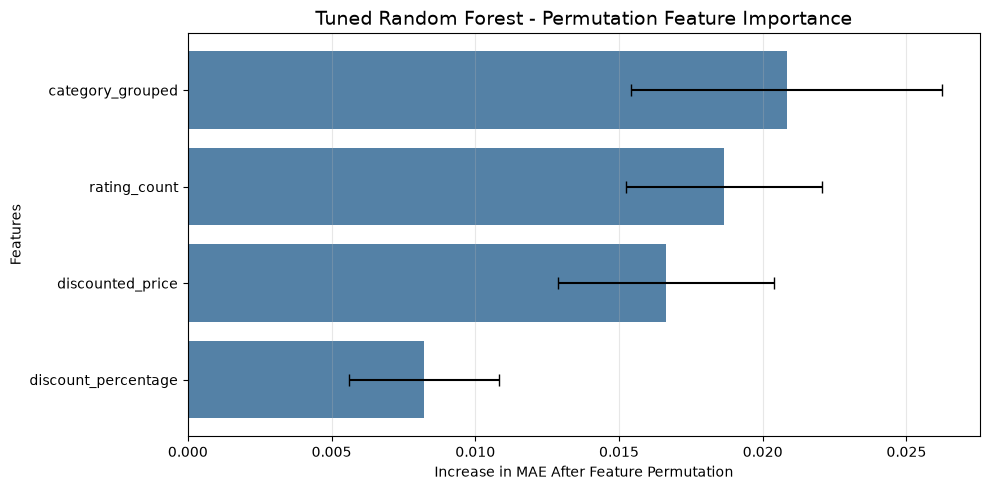

In [45]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=feature_importance_df,
    x="Importance_Mean",
    y="Feature",
    color="steelblue"
)

plt.errorbar(
    x=feature_importance_df["Importance_Mean"],
    y=np.arange(len(feature_importance_df)),
    xerr=feature_importance_df["Importance_Std"],
    fmt="none",
    ecolor="black",
    capsize=4
)

plt.title("Tuned Random Forest - Permutation Feature Importance", fontsize=14)
plt.xlabel("Increase in MAE After Feature Permutation")
plt.ylabel("Features")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig("task6_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

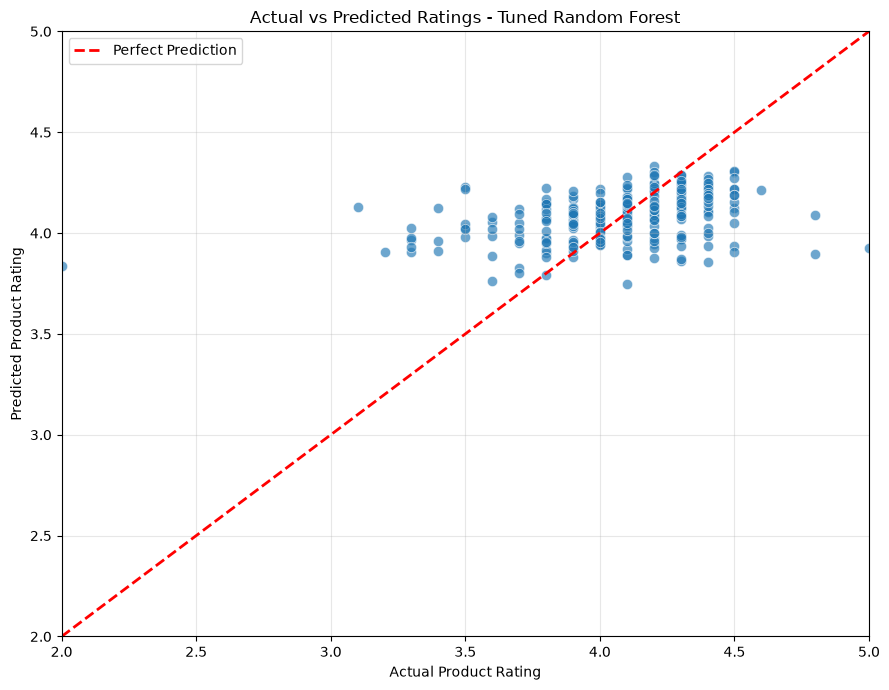

In [46]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    x=y_test,
    y=final_predictions,
    alpha=0.65,
    s=55
)

plt.plot(
    [2, 5],
    [2, 5],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Product Rating")
plt.ylabel("Predicted Product Rating")
plt.title("Actual vs Predicted Ratings - Tuned Random Forest")

plt.xlim(2, 5)
plt.ylim(2, 5)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "task6_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

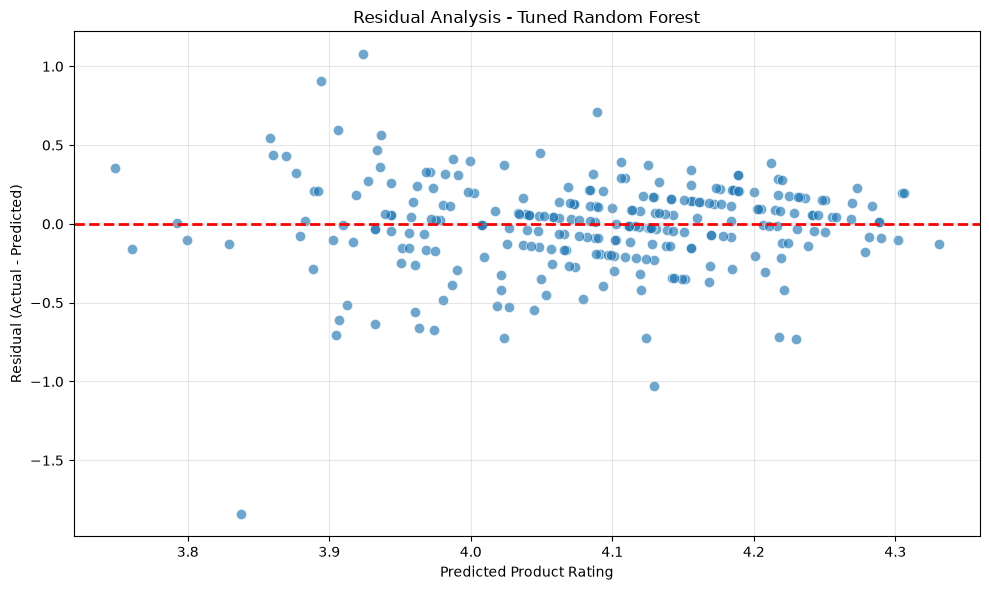

Mean Residual: -0.0113
Residual Standard Deviation: 0.2944
Minimum Residual: -1.8378
Maximum Residual: 1.0761


In [47]:
#Residual Analysis
#Residual = Actual Rating − Predicted Rating
residuals = y_test.to_numpy() - final_predictions

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=final_predictions,
    y=residuals,
    alpha=0.65,
    s=55
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Predicted Product Rating")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Analysis - Tuned Random Forest")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "task6_residual_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Mean Residual:", round(np.mean(residuals), 4))
print("Residual Standard Deviation:", round(np.std(residuals), 4))
print("Minimum Residual:", round(np.min(residuals), 4))
print("Maximum Residual:", round(np.max(residuals), 4))

**Final interpreatation:The residual analysis indicates minimal overall prediction bias, with a mean residual of −0.0113. However, the residual standard deviation of 0.2944 and extreme errors ranging from −1.8378 to +1.0761 demonstrate that individual predictions can be substantially inaccurate. Combined with the rating-group analysis, these findings suggest that the model struggles particularly with extreme product ratings.**

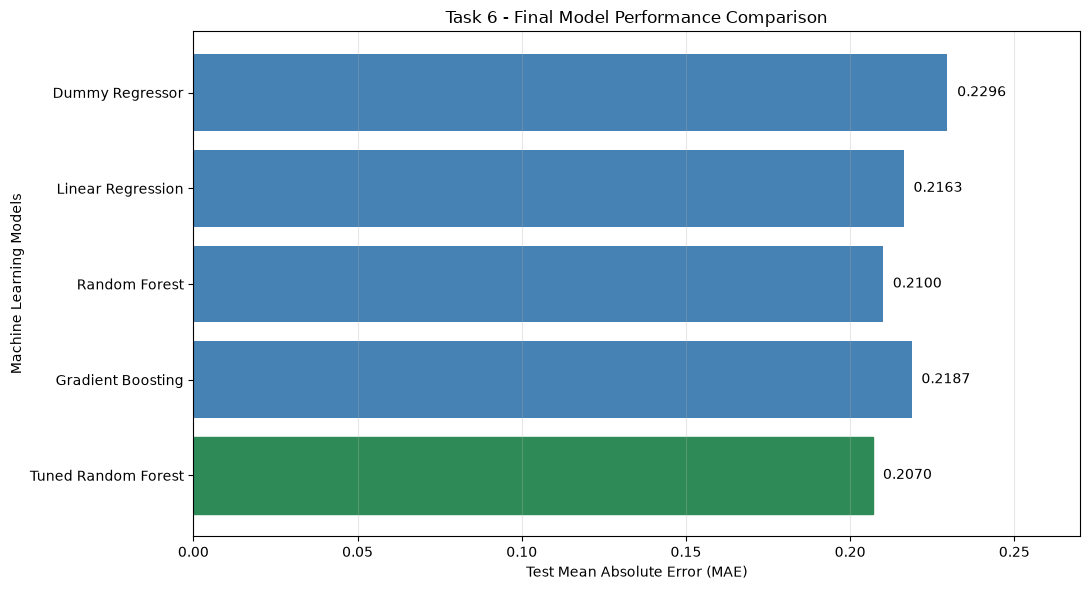

In [48]:
#final model comparision visualisation
model_order = [
    "Dummy Regressor",
    "Linear Regression",
    "Random Forest",
    "Gradient Boosting",
    "Tuned Random Forest"
]

model_mae = [0.2296, 0.2163, 0.2100, 0.2187, 0.2070]

plt.figure(figsize=(11, 6))

bars = plt.barh(model_order, model_mae, color="steelblue")

bars[-1].set_color("seagreen")

plt.xlabel("Test Mean Absolute Error (MAE)")
plt.ylabel("Machine Learning Models")
plt.title("Task 6 - Final Model Performance Comparison")

plt.xlim(0, 0.27)
plt.gca().invert_yaxis()

for bar, value in zip(bars, model_mae):
    plt.text(
        value + 0.003,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center"
    )

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "task6_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Task 6: Predictive Rating Analysis – Final Conclusion

### 1. Project Overview

The objective of this task was to develop a machine learning model to predict Amazon product ratings using discounted price, discount percentage, rating count, and product category. The analysis was conducted on a cleaned dataset containing **1,348 products**, using an 80:20 training-test split.

A preprocessing pipeline was implemented with missing-value imputation, logarithmic transformation, feature scaling, and one-hot encoding. Linear Regression, Random Forest, and Gradient Boosting were evaluated alongside a Dummy Regressor baseline. Hyperparameter tuning was performed on Random Forest using RandomizedSearchCV.

### 2. Model Performance Comparison

| Model | Test MAE | Test RMSE | Test R² |
|---|---:|---:|---:|
| Dummy Regressor | 0.2296 | 0.3193 | -0.0049 |
| Linear Regression | 0.2163 | 0.2995 | 0.1162 |
| Random Forest | 0.2100 | 0.2976 | 0.1275 |
| Gradient Boosting | 0.2187 | 0.3039 | 0.0901 |
| **Tuned Random Forest** | **0.2070** | **0.2947** | **0.1444** |

**Tuned Random Forest achieved the best overall test performance**, with the lowest MAE and RMSE and the highest R². Its five-fold cross-validation results were MAE = 0.1945, RMSE = 0.2661, and R² = 0.1320.

However, the difference between training R² (0.4999) and cross-validation R² (0.1320) indicates overfitting. The test R² of 0.1444 means the model explains approximately 14.44% of rating variation in the held-out dataset.

### 3. Prediction Error Analysis

Rating-group analysis revealed substantial differences in prediction accuracy:

- **Low-rated products:** Highest MAE of 0.7881, indicating systematic overestimation.
- **Medium-rated products:** Lowest MAE of 0.1606, indicating comparatively accurate predictions.
- **High-rated products:** MAE of 0.2083, with a tendency toward underestimation.

Category-wise analysis showed that Home & Kitchen products had the highest MAE (0.2603), while Computers & Accessories had the lowest MAE (0.1751) among well-represented categories.

Residual analysis produced a mean residual of -0.0113 and a standard deviation of 0.2944. Extreme residuals ranged from -1.8378 to +1.0761, demonstrating that some individual predictions were substantially inaccurate.

### 4. Feature Importance

Permutation importance analysis identified the following ranking:

| Feature | Importance |
|---|---:|
| Product Category | 0.02083 |
| Rating Count | 0.01866 |
| Discounted Price | 0.01663 |
| Discount Percentage | 0.00820 |

Product category showed the highest predictive importance, followed by rating count and discounted price. Discount percentage contributed the least among the selected features. These results describe predictive relationships rather than causal effects.

### 5. Business Implications and Practical Limitations

The model provides a useful demonstration of how product attributes can support rating prediction. It may help with exploratory product analysis and identifying broad patterns.

However, its limited R², overfitting concerns, and large errors for low-rated products restrict its reliability for practical decision-making. It should not be used independently for product ranking, quality assessment, or important commercial decisions.

Future improvements could include incorporating review sentiment, brand information, product descriptions, and additional relevant features. More representative data for poorly rated products may also improve prediction performance.

### 6. Final Conclusion

**Tuned Random Forest was the best-performing model among the evaluated approaches**, achieving a test MAE of 0.2070, RMSE of 0.2947, and R² of 0.1444.

Although it outperformed the baseline and other regression models, its predictive accuracy remains limited, particularly for products with unusually low or high ratings.

**Therefore, the model is suitable for educational and exploratory analysis but is not sufficiently reliable for standalone real-world rating prediction or high-impact business decisions.**

In [49]:
final_test_df.to_csv("task6_model_comparison.csv", index=False)

cv_comparison.to_csv("task6_cross_validation.csv", index=False)

error_analysis.to_csv("task6_prediction_errors.csv", index=False)

rating_group_errors.to_csv("task6_rating_group_errors.csv", index=False)

category_error_analysis.to_csv("task6_category_errors.csv", index=False)

feature_importance_df.to_csv("task6_feature_importance.csv", index=False)

print("All Task 6 CSV files exported successfully!")

import os

for file in [
    "task6_model_comparison.csv",
    "task6_cross_validation.csv",
    "task6_prediction_errors.csv",
    "task6_rating_group_errors.csv",
    "task6_category_errors.csv",
    "task6_feature_importance.csv"
]:
    print(file, "| Exists:", os.path.exists(file))

All Task 6 CSV files exported successfully!
task6_model_comparison.csv | Exists: True
task6_cross_validation.csv | Exists: True
task6_prediction_errors.csv | Exists: True
task6_rating_group_errors.csv | Exists: True
task6_category_errors.csv | Exists: True
task6_feature_importance.csv | Exists: True


In [50]:
import joblib
import os

joblib.dump(
    tuned_rf_model,
    "task6_tuned_random_forest.pkl"
)

loaded_model = joblib.load(
    "task6_tuned_random_forest.pkl"
)

original_predictions = tuned_rf_model.predict(X_test)
loaded_predictions = loaded_model.predict(X_test)

print("Model Saved Successfully!")
print("File Exists:", os.path.exists("task6_tuned_random_forest.pkl"))
print("File Size (MB):", round(os.path.getsize("task6_tuned_random_forest.pkl") / (1024 ** 2), 2))
print("Predictions Match:", np.allclose(original_predictions, loaded_predictions))

Model Saved Successfully!
File Exists: True
File Size (MB): 6.05
Predictions Match: True
